# 02 · Exploratory data analysis (EDA) summary

**Phase 1 deliverable: EDA summary (at least 10 charts).** Every chart reads the cleaned PostgreSQL tables (`clean.*`) built by `week1/3_cleaning_and_baselines.sql`, so the numbers match the dashboard and the SQL.

Topics from the plan: **monthly seasonality, the March 2025 stamp duty spike, conversion by channel, overseas share and night-time browsing**, plus reply speed, agent seniority, devices and virtual tours, late payment, deal value and the 12-month baselines. If segments are already loaded (Week 3), one more chart shows **which segments surged before the stamp duty change**.

Each section prints its insight (written from the numbers, so it updates when the data changes).
**Outputs** (folder `reports/02_eda/`): the charts and `Veltrix_EDA_summary.docx`.

In [1]:
# First time only:  %pip install sqlalchemy psycopg2-binary python-docx openpyxl seaborn

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
import vx

vx.connect()
vx.style()
OUT = vx.out_dir("02_eda")
CH = OUT / "charts"
Q = vx.Q
SECTIONS = []          # (heading, chart path, insight) for the Word summary
NUM = {}               # key numbers, saved to eda_numbers.json
PCT = PercentFormatter(1.0, decimals=0)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def insight(heading, path, text):
    SECTIONS.append((heading, path, text))
    display(Markdown("> **Insight:** " + text))

Connected to database 'Veltrix' on localhost:5432 as postgres


## 1. Monthly leads, sales and lettings

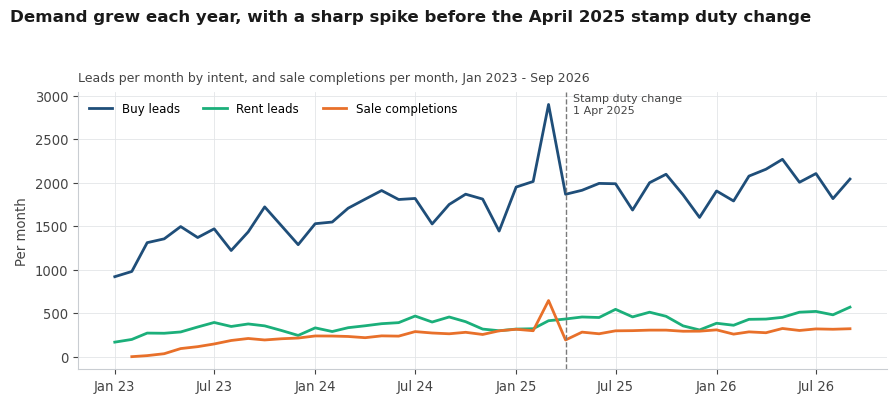

> **Insight:** **Demand grows each year:** leads from January to September rose from 14.2k (2023) to 18.8k (2024) and 22.2k (2025), and stand at 22.3k in 2026. The spike before the dashed line is the March 2025 stamp duty rush; completions spike with it and then fall back.

In [3]:
m = Q("""SELECT date_trunc('month', created_date)::date AS month, intent, count(*) AS leads
         FROM clean.clean_leads GROUP BY 1, 2 ORDER BY 1""").pivot(index="month", columns="intent", values="leads")
m.index = pd.to_datetime(m.index)
comp = Q("""SELECT date_trunc('month', completion_or_move_in_date)::date AS month, count(*) AS completions
            FROM clean.clean_transactions WHERE deal_kind = 'Sale' AND completion_or_move_in_date <= DATE '2026-09-30'
            GROUP BY 1 ORDER BY 1""").set_index("month").completions
comp.index = pd.to_datetime(comp.index)
ytd = {y: int(m.loc[f"{y}-01-01":f"{y}-09-30"].sum().sum()) for y in (2023, 2024, 2025, 2026)}
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(m.index, m["Buy"], color=vx.NAVY, lw=2, label="Buy leads")
ax.plot(m.index, m["Rent"], color=vx.SERIES[2], lw=2, label="Rent leads")
ax.plot(comp.index, comp.values, color=vx.ORANGE, lw=2, label="Sale completions")
ax.axvline(pd.Timestamp("2025-04-01"), color=vx.MUTED, ls="--", lw=1)
ax.annotate("Stamp duty change\n1 Apr 2025", (pd.Timestamp("2025-04-01"), ax.get_ylim()[1] * 0.92), xytext=(5, 0),
            textcoords="offset points", fontsize=8, color=vx.INK2)
ax.legend(loc="upper left", ncol=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
p = vx.finish(fig, ax, "Demand grew each year, with a sharp spike before the April 2025 stamp duty change",
              "Leads per month by intent, and sale completions per month, Jan 2023 - Sep 2026", CH / "01_monthly_trend.png", ylabel="Per month")
NUM["leads_jan_sep"] = ytd
insight("Monthly leads, sales and lettings", p,
        f"**Demand grows each year:** leads from January to September rose from {ytd[2023]/1e3:.1f}k (2023) to {ytd[2024]/1e3:.1f}k (2024) "
        f"and {ytd[2025]/1e3:.1f}k (2025), and stand at {ytd[2026]/1e3:.1f}k in 2026. The spike before the dashed line is the March 2025 "
        f"stamp duty rush; completions spike with it and then fall back.")

## 2. Seasonality index by calendar month

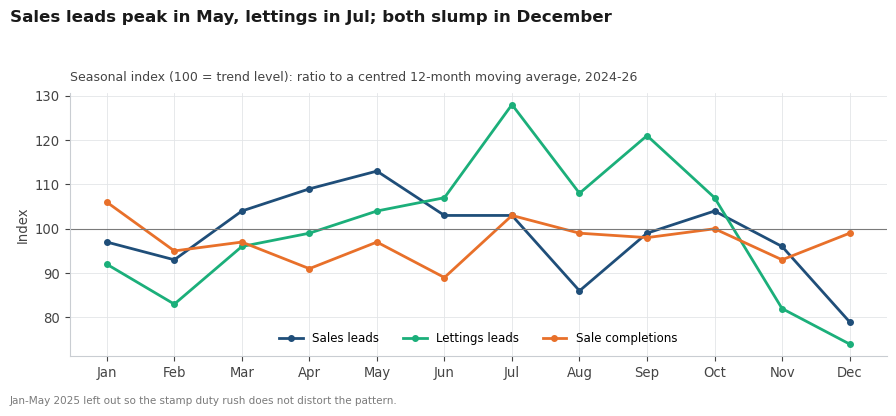

> **Insight:** **Sales and lettings have different seasons.** Sales leads peak in **May (index 113)** and are lowest in Dec (79); lettings leads peak in **Jul (128)**. Marketing budgets and agent rotas should follow these curves rather than a flat monthly plan.

In [4]:
def seasonal_index(series):
    """Ratio to a centred 12-month moving average, averaged by calendar month (2024 onward, without Jan-May 2025)."""
    cma = series.rolling(12, center=True).mean().rolling(2).mean().shift(-1)
    r = (series / cma).dropna()
    r = r[(r.index >= "2024-01-01") & ~((r.index >= "2025-01-01") & (r.index <= "2025-05-01"))]
    return (r.groupby(r.index.month).mean() * 100).round(0)

idx = pd.DataFrame({"Sales leads": seasonal_index(m["Buy"]), "Lettings leads": seasonal_index(m["Rent"]),
                    "Sale completions": seasonal_index(comp)})
fig, ax = plt.subplots(figsize=(9, 4))
for col, colr in zip(idx.columns, [vx.NAVY, vx.SERIES[2], vx.ORANGE]):
    ax.plot(idx.index, idx[col], color=colr, lw=2, marker="o", ms=4, label=col)
ax.axhline(100, color=vx.MUTED, lw=0.8)
ax.set_xticks(range(1, 13), MONTHS)
ax.legend(ncol=3, loc="lower center")
s_pk, l_pk = idx["Sales leads"].idxmax(), idx["Lettings leads"].idxmax()
p = vx.finish(fig, ax, f"Sales leads peak in {MONTHS[s_pk-1]}, lettings in {MONTHS[l_pk-1]}; both slump in December",
              "Seasonal index (100 = trend level): ratio to a centred 12-month moving average, 2024-26", CH / "02_seasonality.png",
              ylabel="Index", note="Jan-May 2025 left out so the stamp duty rush does not distort the pattern.")
NUM["seasonality"] = {c: idx[c].dropna().astype(int).to_dict() for c in idx.columns}
insight("Seasonality", p,
        f"**Sales and lettings have different seasons.** Sales leads peak in **{MONTHS[s_pk-1]} (index {idx['Sales leads'].max():.0f})** "
        f"and are lowest in {MONTHS[idx['Sales leads'].idxmin()-1]} ({idx['Sales leads'].min():.0f}); lettings leads peak in "
        f"**{MONTHS[l_pk-1]} ({idx['Lettings leads'].max():.0f})**. Marketing budgets and agent rotas should follow these curves rather than a flat monthly plan.")

## 3. The stamp duty spike

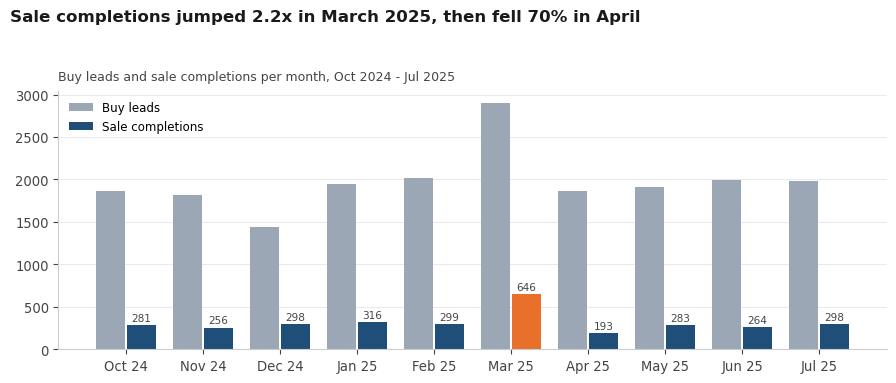

> **Insight:** **The stamp duty change pulled demand forward.** In March 2025 buy leads were **+44%** on February and sale completions **2.2x** February's, then fell **70%** in April. Any year-on-year comparison that includes Q1-Q2 2025 needs this caveat, and the next policy change should trigger an early campaign and a model refresh.

In [5]:
sd = Q("""WITH l AS (SELECT date_trunc('month', created_date)::date mth, count(*) leads FROM clean.clean_leads WHERE intent = 'Buy' GROUP BY 1),
              c AS (SELECT date_trunc('month', completion_or_move_in_date)::date mth, count(*) completions FROM clean.clean_transactions
                    WHERE deal_kind = 'Sale' GROUP BY 1)
         SELECT mth, leads, coalesce(completions, 0) completions FROM l LEFT JOIN c USING (mth)
         WHERE mth BETWEEN DATE '2024-10-01' AND DATE '2025-07-01' ORDER BY mth""")
sd["label"] = pd.to_datetime(sd.mth).dt.strftime("%b %y")
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(sd))
b1 = ax.bar(x - 0.2, sd.leads, 0.38, color=vx.GREY, label="Buy leads")
b2 = ax.bar(x + 0.2, sd.completions, 0.38, color=[vx.ORANGE if l == "Mar 25" else vx.NAVY for l in sd.label], label="Sale completions")
vx.bar_labels(ax, b2, size=7.5)
ax.set_xticks(x, sd.label)
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
s = sd.set_index("label")
c_x = s.loc["Mar 25", "completions"] / s.loc["Feb 25", "completions"]
l_up = s.loc["Mar 25", "leads"] / s.loc["Feb 25", "leads"] - 1
apr = s.loc["Apr 25", "completions"] / s.loc["Mar 25", "completions"] - 1
p = vx.finish(fig, ax, f"Sale completions jumped {c_x:.1f}x in March 2025, then fell {abs(apr):.0%} in April",
              "Buy leads and sale completions per month, Oct 2024 - Jul 2025", CH / "03_stamp_duty.png")
NUM["stamp_duty"] = dict(completions_x=round(c_x, 2), leads_up=round(l_up, 3), april_drop=round(apr, 3))
insight("Stamp duty spike", p,
        f"**The stamp duty change pulled demand forward.** In March 2025 buy leads were **{l_up:+.0%}** on February and sale completions "
        f"**{c_x:.1f}x** February's, then fell **{abs(apr):.0%}** in April. Any year-on-year comparison that includes Q1-Q2 2025 needs this caveat, "
        f"and the next policy change should trigger an early campaign and a model refresh.")

## 4. Conversion by channel

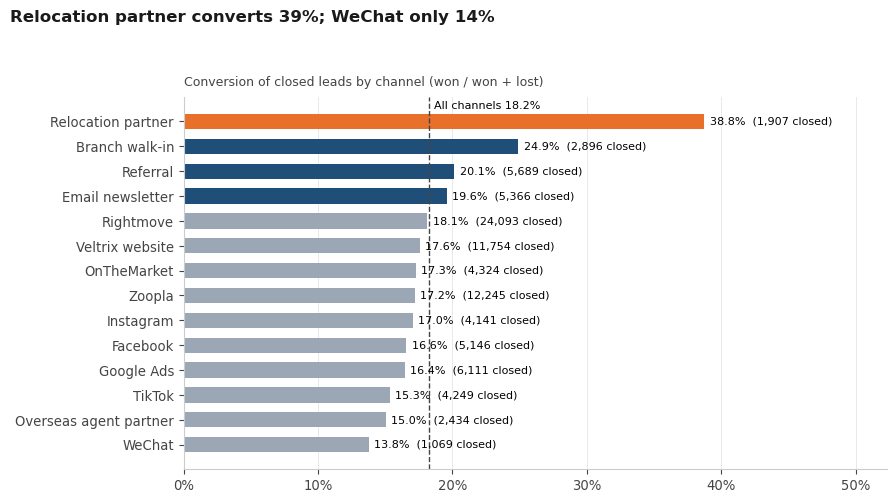

> **Insight:** **Channels convert very differently** (average 18.2%). Relocation partner converts **38.8%** and Branch walk-in 24.9%; WeChat (**13.8%**) and Overseas agent partner (15.0%) convert least. Rightmove brings the most leads (24,093 closed) at 18.1%. Spend should be judged on cost per won deal, not on lead volume.

In [6]:
ch = Q("""SELECT lead_source, count(*) closed, avg(CASE WHEN converted THEN 1.0 ELSE 0 END) conv
          FROM clean.clean_leads WHERE is_closed = 1 GROUP BY 1 ORDER BY conv""")
overall = vx.V("SELECT avg(CASE WHEN converted THEN 1.0 ELSE 0 END) FROM clean.clean_leads WHERE is_closed = 1")
fig, ax = plt.subplots(figsize=(9, 5))
cols = [vx.ORANGE if v >= ch.conv.max() - 1e-9 else (vx.GREY if v < overall else vx.NAVY) for v in ch.conv]
b = ax.barh(ch.lead_source, ch.conv, color=cols, height=0.62)
for bar, nn in zip(b, ch.closed):
    ax.annotate(f"{bar.get_width():.1%}  ({nn:,} closed)", (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
ax.axvline(overall, color=vx.INK2, ls="--", lw=1)
ax.annotate(f"All channels {overall:.1%}", (overall, len(ch) - 0.5), xytext=(4, 0), textcoords="offset points", fontsize=8)
ax.xaxis.set_major_formatter(PCT)
ax.set_xlim(0, ch.conv.max() * 1.35)
ax.grid(axis="y", visible=False)
top, low = ch.iloc[-1], ch.iloc[0]
big = ch.sort_values("closed").iloc[-1]
p = vx.finish(fig, ax, f"{top.lead_source} converts {top.conv:.0%}; {low.lead_source} only {low.conv:.0%}",
              "Conversion of closed leads by channel (won / won + lost)", CH / "04_conversion_by_channel.png")
NUM["conversion_by_channel"] = dict(zip(ch.lead_source, ch.conv.round(4)))
insight("Conversion by channel", p,
        f"**Channels convert very differently** (average {overall:.1%}). {top.lead_source} converts **{top.conv:.1%}** and "
        f"{ch.iloc[-2].lead_source} {ch.iloc[-2].conv:.1%}; {low.lead_source} (**{low.conv:.1%}**) and {ch.iloc[1].lead_source} "
        f"({ch.iloc[1].conv:.1%}) convert least. {big.lead_source} brings the most leads ({big.closed:,} closed) at {big.conv:.1%}. "
        f"Spend should be judged on cost per won deal, not on lead volume.")

## 5. Why the channel chart needed cleaning: raw lead-source spellings

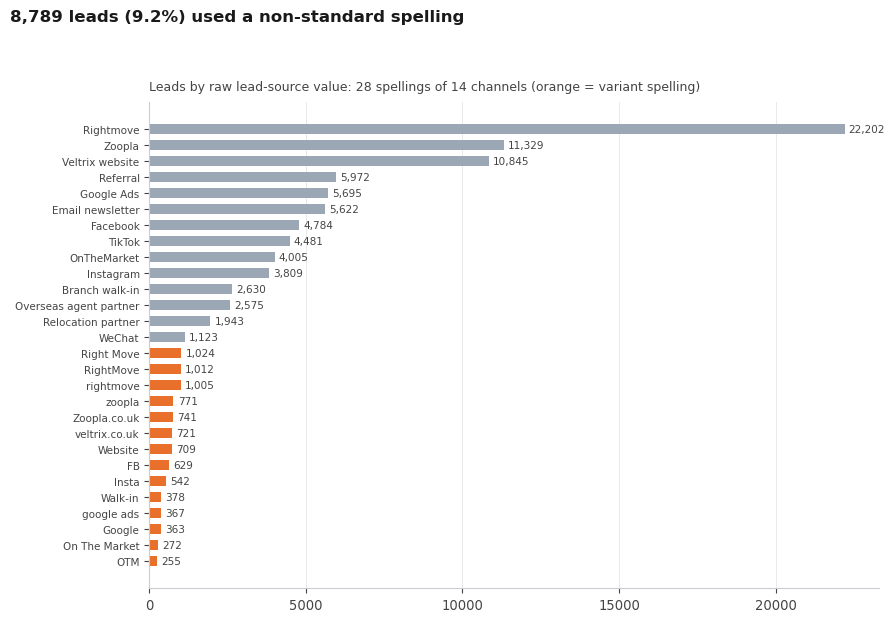

> **Insight:** This is why the cleaning mattered: **8,789 leads (9.2%)** used one of 14 variant spellings. Without the mapping table, Rightmove, Zoopla, OnTheMarket and others would be split across several smaller bars and under-counted.

In [7]:
rs = Q("SELECT lead_source_raw, lead_source, count(*) n FROM clean.clean_leads GROUP BY 1, 2 ORDER BY n")
fig, ax = plt.subplots(figsize=(9, 6.2))
b = ax.barh(rs.lead_source_raw, rs.n, color=[vx.GREY if a == c else vx.ORANGE for a, c in zip(rs.lead_source_raw, rs.lead_source)], height=0.65)
vx.barh_labels(ax, b, size=7.5)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=7.5)
variant = int(rs.loc[rs.lead_source_raw != rs.lead_source, "n"].sum())
p = vx.finish(fig, ax, f"{variant:,} leads ({variant / rs.n.sum():.1%}) used a non-standard spelling",
              f"Leads by raw lead-source value: {len(rs)} spellings of {rs.lead_source.nunique()} channels (orange = variant spelling)",
              CH / "05_raw_spellings.png")
insight("Raw lead-source spellings", p,
        f"This is why the cleaning mattered: **{variant:,} leads ({variant / rs.n.sum():.1%})** used one of "
        f"{(rs.lead_source_raw != rs.lead_source).sum()} variant spellings. Without the mapping table, Rightmove, Zoopla, OnTheMarket and others "
        f"would be split across several smaller bars and under-counted.")

## 6. Conversion by time to first reply

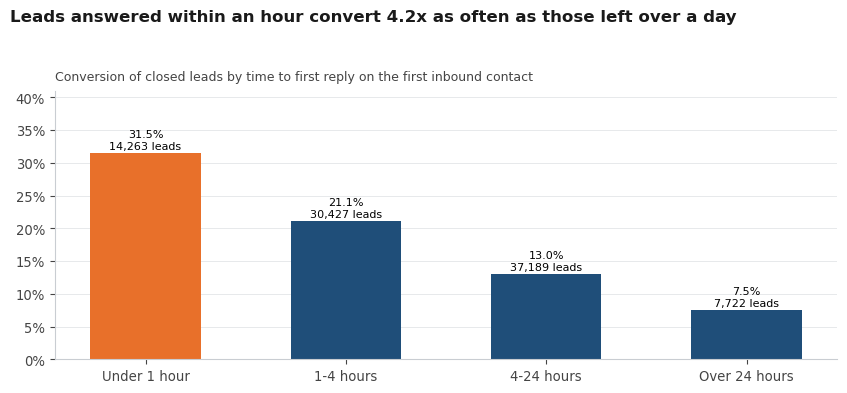

> **Insight:** **Reply speed is the strongest lever in the data.** Leads answered within 1 hour convert at **31.5%**, against **7.5%** when left over 24 hours (4.2x). Yet only **15.9%** of leads get a reply within the hour. Routing priority leads to agents who can answer fast is the quickest win.

In [8]:
rb = Q("""SELECT first_reply_band, count(*) closed, avg(CASE WHEN converted THEN 1.0 ELSE 0 END) conv
          FROM clean.clean_leads WHERE is_closed = 1 AND first_reply_band <> 'Unknown' GROUP BY 1 ORDER BY 1""")
within = vx.V("SELECT avg(CASE WHEN first_response_min < 60 THEN 1.0 ELSE 0 END) FROM clean.clean_leads WHERE first_response_min IS NOT NULL")
fig, ax = plt.subplots(figsize=(8.5, 3.9))
b = ax.bar([x[3:] for x in rb.first_reply_band], rb.conv, color=[vx.ORANGE] + [vx.NAVY] * (len(rb) - 1), width=0.55)
for bar, nn in zip(b, rb.closed):
    ax.annotate(f"{bar.get_height():.1%}\n{nn:,} leads", (bar.get_x() + bar.get_width() / 2, bar.get_height()), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=8)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, rb.conv.max() * 1.3)
ax.grid(axis="x", visible=False)
ratio = rb.conv.iloc[0] / rb.conv.iloc[-1]
p = vx.finish(fig, ax, f"Leads answered within an hour convert {ratio:.1f}x as often as those left over a day",
              "Conversion of closed leads by time to first reply on the first inbound contact", CH / "06_reply_speed.png")
NUM["reply"] = dict(conv_under_1h=round(rb.conv.iloc[0], 4), conv_over_24h=round(rb.conv.iloc[-1], 4), share_within_1h=round(within, 4))
insight("Reply speed", p,
        f"**Reply speed is the strongest lever in the data.** Leads answered within 1 hour convert at **{rb.conv.iloc[0]:.1%}**, against "
        f"**{rb.conv.iloc[-1]:.1%}** when left over 24 hours ({ratio:.1f}x). Yet only **{within:.1%}** of leads get a reply within the hour. "
        f"Routing priority leads to agents who can answer fast is the quickest win.")

## 7. Agent seniority

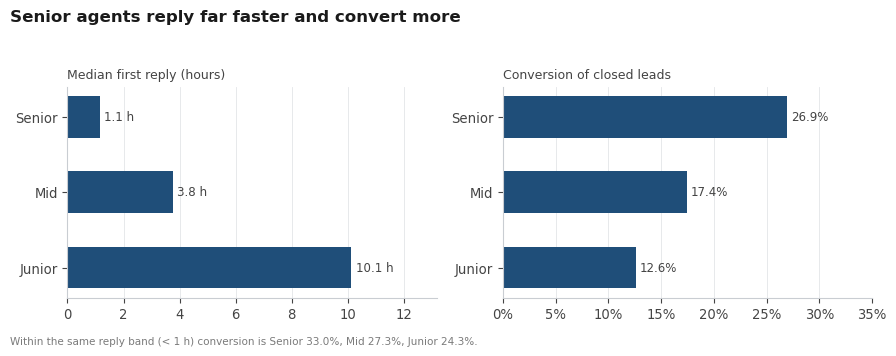

> **Insight:** **Senior agents reply faster** (median **1.1 h**, against 3.8 h for mid-level and **10.1 h** for juniors) **and convert more** (26.9% vs 17.4% vs 12.6%). When every agent replies within an hour the gap narrows (33.0% vs 24.3%), so much of the seniority advantage is speed, which juniors can be coached on.

In [9]:
ag = Q("""SELECT a.seniority, percentile_cont(0.5) WITHIN GROUP (ORDER BY l.first_response_min) med_reply,
                 avg(CASE WHEN l.converted THEN 1.0 ELSE 0 END) conv, count(*) closed,
                 avg(CASE WHEN l.converted THEN 1.0 ELSE 0 END) FILTER (WHERE l.first_response_min < 60) conv_fast
          FROM clean.clean_leads l JOIN clean.clean_agents a USING (agent_id)
          WHERE l.is_closed = 1 GROUP BY 1""").set_index("seniority").loc[["Senior", "Mid", "Junior"]]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
b1 = axes[0].barh(ag.index[::-1], ag.med_reply[::-1] / 60, color=vx.NAVY, height=0.55)
vx.barh_labels(axes[0], b1, "{:.1f} h")
axes[0].set_title("Median first reply (hours)", loc="left", fontsize=9, color=vx.INK2)
axes[0].set_xlim(0, ag.med_reply.max() / 60 * 1.3)
b2 = axes[1].barh(ag.index[::-1], ag.conv[::-1], color=vx.NAVY, height=0.55)
vx.barh_labels(axes[1], b2, "{:.1%}")
axes[1].set_title("Conversion of closed leads", loc="left", fontsize=9, color=vx.INK2)
axes[1].xaxis.set_major_formatter(PCT)
axes[1].set_xlim(0, ag.conv.max() * 1.3)
for a in axes:
    a.grid(axis="y", visible=False)
p = vx.finish(fig, axes[0], "Senior agents reply far faster and convert more", "", CH / "07_seniority.png",
              note="Within the same reply band (< 1 h) conversion is " + ", ".join(f"{k} {v:.1%}" for k, v in ag.conv_fast.items()) + ".")
insight("Agent seniority", p,
        f"**Senior agents reply faster** (median **{ag.med_reply['Senior']/60:.1f} h**, against {ag.med_reply['Mid']/60:.1f} h for mid-level and "
        f"**{ag.med_reply['Junior']/60:.1f} h** for juniors) **and convert more** ({ag.conv['Senior']:.1%} vs {ag.conv['Mid']:.1%} vs {ag.conv['Junior']:.1%}). "
        f"When every agent replies within an hour the gap narrows ({ag.conv_fast['Senior']:.1%} vs {ag.conv_fast['Junior']:.1%}), so much of the "
        f"seniority advantage is speed, which juniors can be coached on.")

## 8. Overseas share

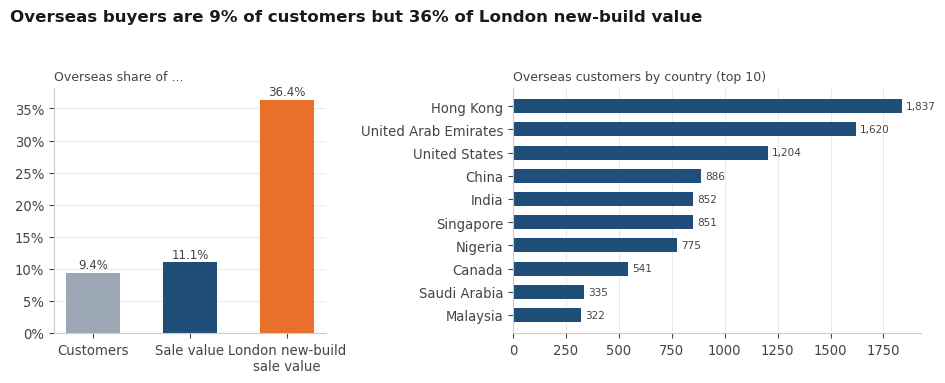

> **Insight:** **Overseas customers punch above their weight:** 9.4% of customers, 11.1% of sale value and **36% of London new-build sale value**. Hong Kong (1,837), United Arab Emirates (1,620) and United States (1,204) are the top countries. A dedicated international desk is worth it.

In [10]:
ov = Q("""SELECT avg(CASE WHEN c.is_overseas THEN 1.0 ELSE 0 END) AS share_customers,
                 (SELECT sum(CASE WHEN cc.is_overseas THEN t.deal_value_gbp END) / sum(t.deal_value_gbp)
                  FROM clean.clean_transactions t JOIN clean.clean_customers cc USING (customer_id) WHERE t.deal_kind = 'Sale') AS share_sale_value
          FROM clean.clean_customers c""").iloc[0]
lnb = vx.V("""SELECT sum(CASE WHEN c.is_overseas THEN t.deal_value_gbp END) / sum(t.deal_value_gbp)
              FROM clean.clean_transactions t JOIN clean.clean_customers c USING (customer_id)
              JOIN clean.clean_properties p USING (property_id) JOIN clean.clean_locations lo USING (location_id)
              WHERE t.deal_kind = 'Sale' AND p.new_build AND lo.region = 'London'""")
cty = Q("""SELECT country_of_residence, count(*) n FROM clean.clean_customers WHERE is_overseas GROUP BY 1 ORDER BY n DESC""")
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), gridspec_kw={"width_ratios": [1, 1.5]})
lab = ["Customers", "Sale value", "London new-build\nsale value"]
vals = [ov.share_customers, ov.share_sale_value, lnb]
b = axes[0].bar(lab, vals, color=[vx.GREY, vx.NAVY, vx.ORANGE], width=0.55)
vx.bar_labels(axes[0], b, "{:.1%}")
axes[0].yaxis.set_major_formatter(PCT)
axes[0].set_title("Overseas share of ...", loc="left", fontsize=9, color=vx.INK2)
axes[0].grid(axis="x", visible=False)
c10 = cty.head(10).iloc[::-1]
b = axes[1].barh(c10.country_of_residence, c10.n, color=vx.NAVY, height=0.6)
vx.barh_labels(axes[1], b, size=7.5)
axes[1].set_title("Overseas customers by country (top 10)", loc="left", fontsize=9, color=vx.INK2)
axes[1].grid(axis="y", visible=False)
p = vx.finish(fig, axes[0], f"Overseas buyers are {ov.share_customers:.0%} of customers but {lnb:.0%} of London new-build value", "",
              CH / "08_overseas.png")
NUM["overseas"] = dict(share_customers=round(ov.share_customers, 4), share_sale_value=round(ov.share_sale_value, 4), london_new_build=round(lnb, 4))
insight("Overseas share", p,
        f"**Overseas customers punch above their weight:** {ov.share_customers:.1%} of customers, {ov.share_sale_value:.1%} of sale value and "
        f"**{lnb:.0%} of London new-build sale value**. {cty.iloc[0].country_of_residence} ({cty.iloc[0].n:,}), {cty.iloc[1].country_of_residence} "
        f"({cty.iloc[1].n:,}) and {cty.iloc[2].country_of_residence} ({cty.iloc[2].n:,}) are the top countries. A dedicated international desk is worth it.")

## 9. Night-time browsing by hour

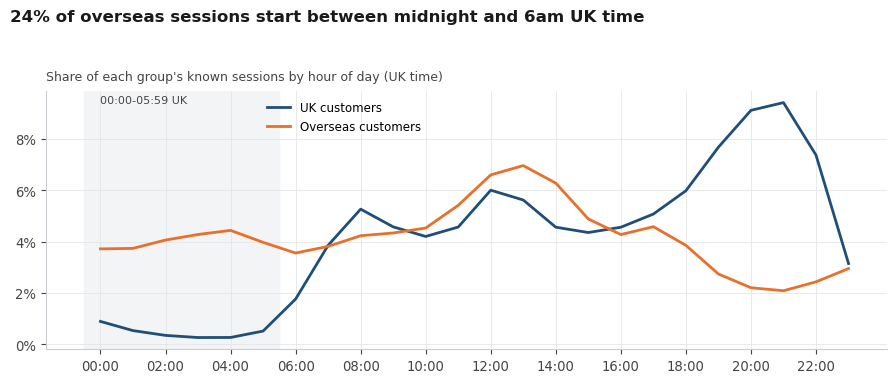

> **Insight:** **Overseas customers browse while the UK sleeps:** **24%** of their sessions start between midnight and 6am, against 3% for UK customers, and their busiest hour is 13:00 UK time. Overnight auto-replies, next-morning call-backs and campaigns timed for Asian and Gulf daytime would serve them better.

In [11]:
nh = Q("""SELECT CASE WHEN c.is_overseas THEN 'Overseas customers' ELSE 'UK customers' END grp, w.session_hour_uk h, count(*) n
          FROM clean.clean_web_sessions w JOIN clean.clean_customers c USING (customer_id) GROUP BY 1, 2""")
nh["share"] = nh.n / nh.groupby("grp").n.transform("sum")
pv = nh.pivot(index="h", columns="grp", values="share")
night = pv.loc[0:5].sum()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axvspan(-0.5, 5.5, color="#F3F4F6", zorder=0)
ax.plot(pv.index, pv["UK customers"], color=vx.NAVY, lw=2, label="UK customers")
ax.plot(pv.index, pv["Overseas customers"], color=vx.ORANGE, lw=2, label="Overseas customers")
ax.annotate("00:00-05:59 UK", (0, ax.get_ylim()[1] * 0.95), fontsize=8, color=vx.INK2)
ax.set_xticks(range(0, 24, 2), [f"{h:02d}:00" for h in range(0, 24, 2)])
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.legend(loc="upper left", bbox_to_anchor=(0.25, 1))
p = vx.finish(fig, ax, f"{night['Overseas customers']:.0%} of overseas sessions start between midnight and 6am UK time",
              "Share of each group's known sessions by hour of day (UK time)", CH / "09_night_browsing.png")
NUM["night_share"] = night.round(4).to_dict()
insight("Night-time browsing", p,
        f"**Overseas customers browse while the UK sleeps:** **{night['Overseas customers']:.0%}** of their sessions start between midnight and 6am, "
        f"against {night['UK customers']:.0%} for UK customers, and their busiest hour is {pv['Overseas customers'].idxmax():02d}:00 UK time. "
        f"Overnight auto-replies, next-morning call-backs and campaigns timed for Asian and Gulf daytime would serve them better.")

## 10. Devices and virtual tours

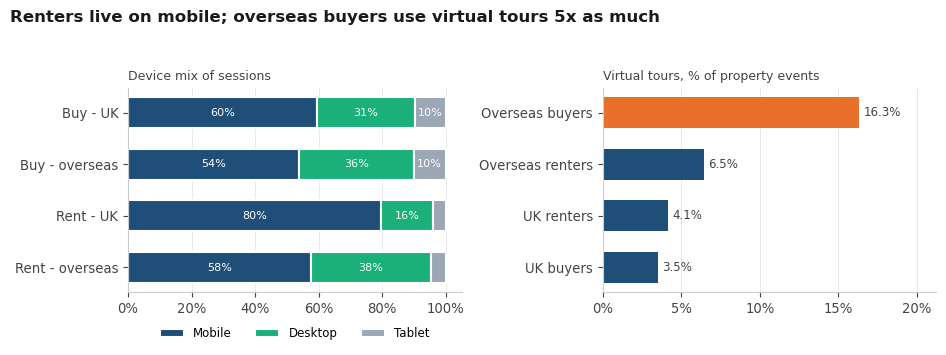

> **Insight:** **Renters live on mobile:** 80% of UK renters' sessions are on mobile against 60% for UK buyers. **Overseas buyers rely on virtual tours** (16.3% of their property events, against 3.5% for UK buyers). Mobile-first pages for lettings and a virtual tour on every new-build and London listing follow directly.

In [12]:
dv = Q("""SELECT c.primary_intent || CASE WHEN c.is_overseas THEN ' - overseas' ELSE ' - UK' END grp, w.device, count(*) n
          FROM clean.clean_web_sessions w JOIN clean.clean_customers c USING (customer_id) GROUP BY 1, 2""")
dv["share"] = dv.n / dv.groupby("grp").n.transform("sum")
dp = dv.pivot(index="grp", columns="device", values="share")[["Mobile", "Desktop", "Tablet"]].sort_index(ascending=False)
vt = Q("""SELECT CASE WHEN c.is_overseas THEN 'Overseas' ELSE 'UK' END || ' ' || lower(c.primary_intent) || 'ers' grp,
                 sum(p.n_virtual_tours)::float / sum(p.n_property_events) vt
          FROM feat.customer_property_view_summary p JOIN clean.clean_customers c USING (customer_id) GROUP BY 1 ORDER BY 2""")
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
left = np.zeros(len(dp))
for dev, col in zip(dp.columns, [vx.NAVY, vx.SERIES[2], vx.GREY]):
    axes[0].barh(dp.index, dp[dev], left=left, color=col, label=dev, height=0.6, edgecolor="white", linewidth=1.5)
    for i, (l, v) in enumerate(zip(left, dp[dev])):
        if v > 0.08:
            axes[0].text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white")
    left += dp[dev].values
axes[0].xaxis.set_major_formatter(PCT)
axes[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
axes[0].set_title("Device mix of sessions", loc="left", fontsize=9, color=vx.INK2)
axes[0].grid(axis="y", visible=False)
b = axes[1].barh(vt.grp, vt.vt, color=[vx.ORANGE if "Overseas buy" in g else vx.NAVY for g in vt.grp], height=0.6)
vx.barh_labels(axes[1], b, "{:.1%}")
axes[1].xaxis.set_major_formatter(PCT)
axes[1].set_xlim(0, vt.vt.max() * 1.3)
axes[1].set_title("Virtual tours, % of property events", loc="left", fontsize=9, color=vx.INK2)
axes[1].grid(axis="y", visible=False)
ukr, ukb = dp.loc["Rent - UK", "Mobile"], dp.loc["Buy - UK", "Mobile"]
vto, vtu = vt.set_index("grp").vt.get("Overseas buyers", np.nan), vt.set_index("grp").vt.get("UK buyers", np.nan)
p = vx.finish(fig, axes[0], f"Renters live on mobile; overseas buyers use virtual tours {vto / vtu:.0f}x as much", "", CH / "10_devices_tours.png")
insight("Devices and virtual tours", p,
        f"**Renters live on mobile:** {ukr:.0%} of UK renters' sessions are on mobile against {ukb:.0%} for UK buyers. "
        f"**Overseas buyers rely on virtual tours** ({vto:.1%} of their property events, against {vtu:.1%} for UK buyers). "
        f"Mobile-first pages for lettings and a virtual tour on every new-build and London listing follow directly.")

## 11. Late payment by month due

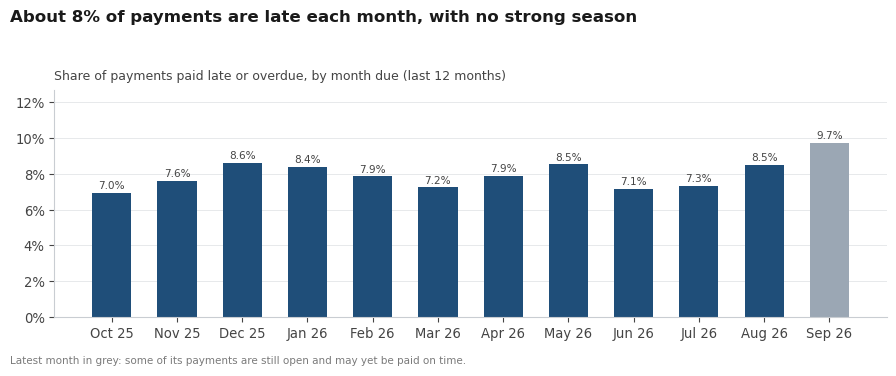

> **Insight:** **Late payment is steady at about 7%-10% a month.** The latest month is not final. Monthly rent is paid late **9.9%** of the time against 3.6% for other payments, so the late-payment problem is mainly a lettings problem (Week 3 shows which tenancy types drive it).

In [13]:
lp = Q("""SELECT date_trunc('month', due_date)::date mth, count(*) n, avg(is_late_or_overdue) late
          FROM clean.clean_payments WHERE due_date BETWEEN DATE '2025-10-01' AND DATE '2026-09-30' AND status <> 'Scheduled'
          GROUP BY 1 ORDER BY 1""")
lp["label"] = pd.to_datetime(lp.mth).dt.strftime("%b %y")
rent_late = vx.V("SELECT avg(is_late_or_overdue) FROM clean.clean_payments WHERE status <> 'Scheduled' AND payment_type = 'Monthly rent'")
oth_late = vx.V("SELECT avg(is_late_or_overdue) FROM clean.clean_payments WHERE status <> 'Scheduled' AND payment_type <> 'Monthly rent'")
fig, ax = plt.subplots(figsize=(9, 3.6))
b = ax.bar(lp.label, lp.late, color=[vx.GREY if i == len(lp) - 1 else vx.NAVY for i in range(len(lp))], width=0.6)
vx.bar_labels(ax, b, "{:.1%}", size=7.5)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, lp.late.max() * 1.3)
ax.grid(axis="x", visible=False)
p = vx.finish(fig, ax, f"About {lp.late.median():.0%} of payments are late each month, with no strong season",
              "Share of payments paid late or overdue, by month due (last 12 months)", CH / "11_late_payment.png",
              note="Latest month in grey: some of its payments are still open and may yet be paid on time.")
NUM["late"] = dict(rent=round(rent_late, 4), other=round(oth_late, 4))
insight("Late payment", p,
        f"**Late payment is steady at about {lp.late.min():.0%}-{lp.late.max():.0%} a month.** The latest month is not final. "
        f"Monthly rent is paid late **{rent_late:.1%}** of the time against {oth_late:.1%} for other payments, so the late-payment problem is "
        f"mainly a lettings problem (Week 3 shows which tenancy types drive it).")

## 12. Deal value by transaction type

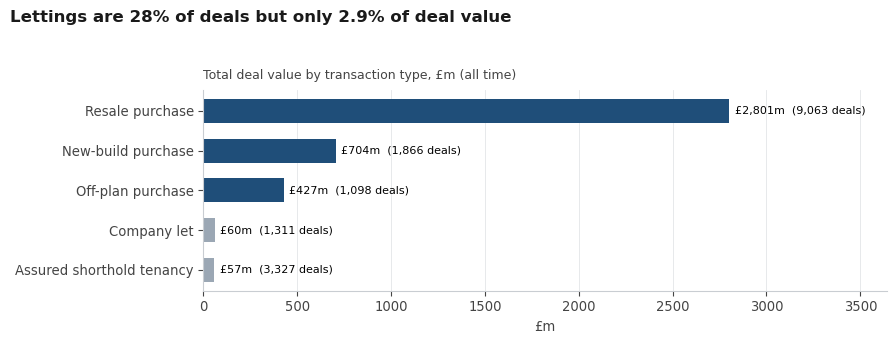

> **Insight:** **Lettings bring volume, not value:** 28% of deals but **2.9%** of deal value (£117.2m of £4.05bn). Resale purchase dominates value at £2.80bn (9,063 deals).

In [14]:
tv = Q("SELECT transaction_type, count(*) deals, sum(deal_value_gbp) val FROM clean.clean_transactions GROUP BY 1 ORDER BY val")
lets = tv.transaction_type.isin(["Assured shorthold tenancy", "Company let"])
fig, ax = plt.subplots(figsize=(9, 3.4))
b = ax.barh(tv.transaction_type, tv.val / 1e6, color=[vx.GREY if l else vx.NAVY for l in lets], height=0.6)
for bar, d in zip(b, tv.deals):
    ax.annotate(f"£{bar.get_width():,.0f}m  ({d:,} deals)", (bar.get_width(), bar.get_y() + bar.get_height() / 2), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8)
ax.set_xlim(0, tv.val.max() / 1e6 * 1.3)
ax.grid(axis="y", visible=False)
let_d, let_v = tv[lets].deals.sum() / tv.deals.sum(), tv[lets].val.sum() / tv.val.sum()
p = vx.finish(fig, ax, f"Lettings are {let_d:.0%} of deals but only {let_v:.1%} of deal value",
              "Total deal value by transaction type, £m (all time)", CH / "12_deal_value.png", xlabel="£m")
insight("Deal value by type", p,
        f"**Lettings bring volume, not value:** {let_d:.0%} of deals but **{let_v:.1%}** of deal value ({vx.gbp(tv[lets].val.sum())} of {vx.gbp(tv.val.sum())}). "
        f"{tv.iloc[-1].transaction_type} dominates value at {vx.gbp(tv.iloc[-1].val)} ({tv.iloc[-1].deals:,} deals).")

## 13. Timing by segment: who surged before the stamp duty change? (needs Week 3, file 10 STEP 7)

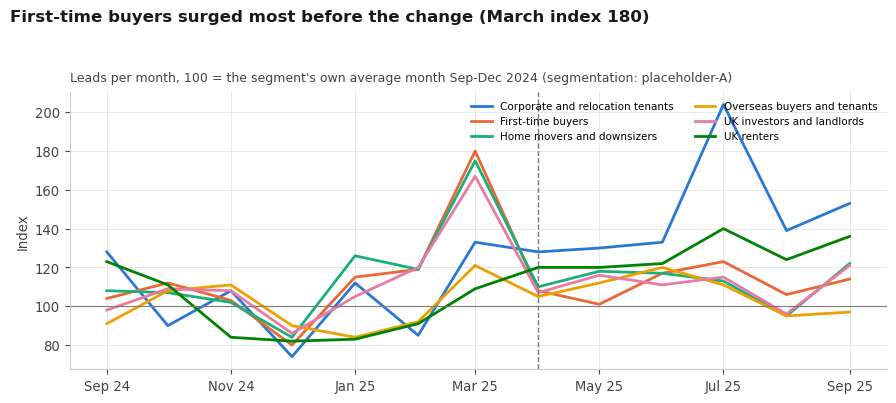

> **Insight:** **Segments did not rush equally.** In March 2025 First-time buyers ran at **180** (100 = a normal month) and Home movers and downsizers at 175, while UK renters stayed near 109. Before the next tax change, these are the segments to contact early.

In [15]:
if vx.exists("clean.segment_stamp_duty"):
    ss = Q("SELECT segment_name, month, leads_index FROM clean.segment_stamp_duty ORDER BY month")
    ss["month"] = pd.to_datetime(ss.month)
    piv = ss.pivot(index="month", columns="segment_name", values="leads_index")
    order = piv.loc["2025-03-01"].sort_values(ascending=False).index
    fig, ax = plt.subplots(figsize=(9, 4))
    for i, sname in enumerate(sorted(piv.columns)):
        ax.plot(piv.index, piv[sname], lw=2, color=vx.SERIES[i % 8], label=sname)
    ax.axhline(100, color=vx.MUTED, lw=0.8)
    ax.axvline(pd.Timestamp("2025-04-01"), color=vx.MUTED, ls="--", lw=1)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    ax.legend(fontsize=7.5, ncol=2, loc="upper right")
    model = vx.segment_model()
    p = vx.finish(fig, ax, f"{order[0]} surged most before the change (March index {piv.loc['2025-03-01', order[0]]:.0f})",
                  f"Leads per month, 100 = the segment's own average month Sep-Dec 2024 (segmentation: {model})",
                  CH / "13_stamp_duty_by_segment.png", ylabel="Index")
    NUM["stamp_duty_by_segment"] = piv.loc["2025-03-01"].round(0).to_dict()
    insight("Timing by segment", p,
            f"**Segments did not rush equally.** In March 2025 {order[0]} ran at **{piv.loc['2025-03-01', order[0]]:.0f}** "
            f"(100 = a normal month) and {order[1]} at {piv.loc['2025-03-01', order[1]]:.0f}, while {order[-1]} stayed near "
            f"{piv.loc['2025-03-01', order[-1]]:.0f}. Before the next tax change, these are the segments to contact early.")
else:
    print("clean.segment_stamp_duty not found: run STEP 7 of week3/10_segment_profiles.sql to add this chart.")

## 14. The 12-month baselines (Oct 2025 - Sep 2026)

In [16]:
base = Q("SELECT kpi, value, definition FROM clean.kpi_baselines ORDER BY kpi_order")
NUM["baselines"] = dict(zip(base.kpi, base.value.astype(float)))
base

,kpi,value,definition
0,"Lead-to-sale conversion (buy leads), %",15.69,"Won / (Won + Lost), buy leads closed in the 12..."
1,"Lead-to-deal conversion (all leads), %",17.77,"Won / (Won + Lost), all leads closed in the 12..."
2,"Median first reply, hours",4.08,"Reply time on the first inbound contact, leads..."
3,"Leads answered within 1 hour, %",15.60,Share of leads with a first reply under 60 min...
4,Median days to close (won leads),41.00,"Lead created to lead closed, won leads"
5,"Cost per campaign lead, £",64.59,Spend of campaigns starting in the 12 months /...
6,"Campaign spend, £",618341.51,Campaigns starting in the 12 months
7,Campaign-attributed leads,9574.00,Leads created in the 12 months with a campaign_id


In [17]:
(OUT / "eda_numbers.json").write_text(json.dumps(NUM, indent=2, default=str), encoding="utf-8")
print(f"{len(SECTIONS)} charts; numbers saved to reports/02_eda/eda_numbers.json")

13 charts; numbers saved to reports/02_eda/eda_numbers.json


## The EDA summary (Word)

In [18]:
r = vx.Report("EDA summary", "Phase 1 · Exploratory data analysis",
              f"{len(SECTIONS)} charts · cleaned PostgreSQL data to 30 Sep 2026 · generated by notebooks/02_eda_summary.ipynb")
r.h1("Key findings")
r.kpis([(f"{NUM['reply']['conv_under_1h']:.0%}", "conversion when answered < 1 h"),
        (f"{NUM['reply']['share_within_1h']:.0%}", "of leads answered < 1 h"),
        (f"{NUM['stamp_duty']['completions_x']:.1f}x", "sale completions, Mar vs Feb 2025"),
        (f"{NUM['overseas']['london_new_build']:.0%}", "of London new-build value from overseas")])
r.bullets([s[2] for s in SECTIONS[:1]] + [SECTIONS[5][2], SECTIONS[2][2], SECTIONS[7][2], SECTIONS[3][2]])
r.callout("**What this means for the segmentation:** reply speed, channel, residence (UK or overseas), browsing hours, device and "
          "virtual-tour use all separate customers strongly, so they belong in the feature set (Phase 2). Seasonality and the "
          "stamp duty spike are timing effects: they shape when to act, not who the segments are.")
r.h1("12-month baselines (Oct 2025 - Sep 2026)")
r.p("These are the 'before' numbers the project will be measured against.")
r.table(base.rename(columns={"kpi": "KPI", "value": "Value", "definition": "Definition"}), widths_cm=[6, 2.5, 8.5])
for i, (h, path, text) in enumerate(SECTIONS, start=1):
    r.h1(f"{i}. {h}")
    r.image(path, h)
    r.p(text)
r.save(OUT / "Veltrix_EDA_summary.docx")

Saved reports\02_eda\Veltrix_EDA_summary.docx
